# AlloyGPT for IN718: evaluation

Uses the run produced by `1_train_AlloyGPT_IN718.ipynb` (folder `training_resu/`):

1. Training and validation loss curves
2. Ground truth and prompts from the held-out test set
3. Load the best checkpoint
4. **Forward prediction**: composition → MeanYS / StdYS / DeltaYS, compared with ground truth
5. **Inverse design**: property targets → composition, compared with the test alloys
6. **Round-trip check**: generated compositions are fed back through the forward task and the predicted
   properties are compared with the targets they were generated for

All outputs are written to `SAVE_DIR`.

> **Note:** This notebook shows how the trained AlloyGPT model is evaluated (loss curves, forward prediction, inverse
> design and the round-trip check) and what the expected output looks like. The outputs saved here come from the
> original run. The training and test data were computed with Thermo-Calc, and its license does not allow us to
> redistribute them, so **no dataset, tokenizer or trained weights are provided**, and this notebook cannot be re-run
> as is. Users with a Thermo-Calc license can generate data in the same format (see "What you need to provide" in the
> README), train the model with `1_train_AlloyGPT_IN718.ipynb`, and then evaluate it here.

In [16]:
import os
import re

import numpy as np
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.metrics import r2_score
from tqdm import tqdm
from transformers import PreTrainedTokenizerFast

from AlloyGPT.ModelPack_v4 import GPTConfig, GPT

TRAIN_RESULT_DIR = './training_resu_v12'      # wk_path of the training notebook
SAVE_DIR = './validation_results'         # where predictions, tables and figures go
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 16                           # adjust for your GPU memory
TEMP_PRED = 1.0                           # sampling temperature, forward prediction
TEMP_GENE = 2.0                           # sampling temperature, inverse design
N_EVAL = 100                             # test records evaluated per task (None = whole test set)

os.makedirs(SAVE_DIR, exist_ok=True)

## 1. Training and validation loss

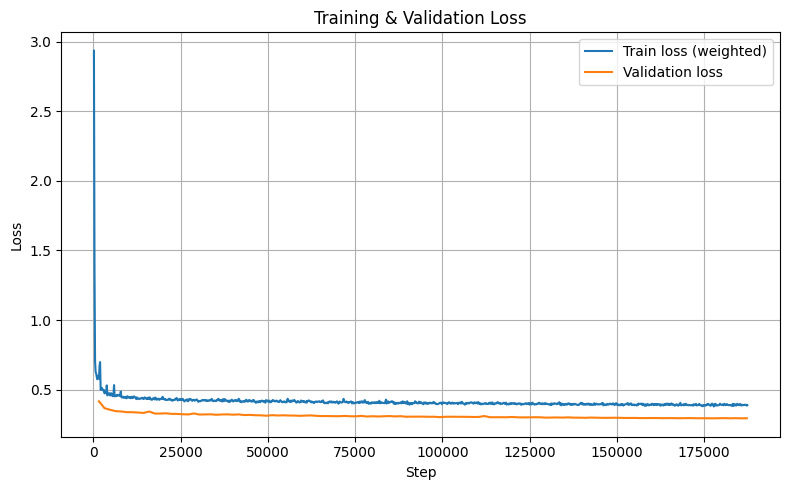

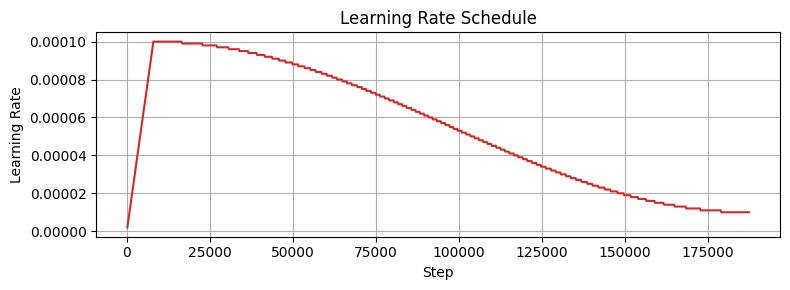

In [2]:
train_df = pd.read_csv(os.path.join(TRAIN_RESULT_DIR, "1_model/training_dir/1_train_loss.log"))
val_df = pd.read_csv(os.path.join(TRAIN_RESULT_DIR, "1_model/training_dir/2_vali_loss.log"))

plt.figure(figsize=(8, 5))
plt.plot(train_df["step"], train_df["wei_loss_trai"], label="Train loss (weighted)", color="tab:blue")
plt.plot(val_df["step"], val_df["loss_eval"], label="Validation loss", color="tab:orange")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(train_df["step"], train_df["lr"], color="tab:red")
plt.xlabel("Step")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Schedule")
plt.grid(True)
plt.tight_layout()
plt.show()

## 2. Ground truth and prompts from the test set

In [3]:
DATALOADER_PATH = os.path.join(TRAIN_RESULT_DIR, "0_dataprocess/test_dataloader.pt")
TOKENIZER_JSON = os.path.join(TRAIN_RESULT_DIR, "0_dataprocess/tokenizer/tokenizer.json")

tokenizer = PreTrainedTokenizerFast(tokenizer_file=TOKENIZER_JSON)
test_dataloader = torch.load(DATALOADER_PATH, map_location="cpu", weights_only=False)

# decode the tokenized test set back into sentences
decoded_prompts = []
for batch in test_dataloader:
    decoded_prompts.extend(tokenizer.batch_decode(batch["input_ids"].tolist(), skip_special_tokens=True))
df = pd.DataFrame({"prompt": decoded_prompts})
print(len(df), "test sentences")

49500 test sentences


In [4]:
def parse_prompt(line: str):
    """Sentence -> dict with Task, MeanYS, StdYS, DeltaYS and the element amounts."""
    result = {}

    task_match = re.search(r"\{Task:(.*?)\}", line)
    if task_match:
        result["Task"] = task_match.group(1)

    prop_match = re.search(r"Property:\[(.*?)\]", line)
    if prop_match:
        for p in prop_match.group(1).split(","):
            k, v = p.split(":")
            k = k.strip().replace("MeanYs", "MeanYS")  # normalise the name
            result[k] = float(v)

    comp_match = re.search(r"Composition:\[(.*?)\]", line)
    if comp_match:
        for c in comp_match.group(1).split(","):
            k, v = c.replace("(", "").replace(")", "").split(":")
            result[k.strip()] = float(v)

    return result


def safe_parse(line: str):
    """parse_prompt that returns an empty record (all NaN) instead of raising on a malformed line."""
    try:
        return parse_prompt(line)
    except Exception:
        return {}


df_parsed = pd.DataFrame([parse_prompt(line) for line in df["prompt"]])

df_gene_gt = df_parsed[df_parsed["Task"].str.contains("Gene")].reset_index(drop=True)
df_pred_gt = df_parsed[df_parsed["Task"].str.contains("Pred")].reset_index(drop=True)
# limit how many test records are generated for (same records every run)
if N_EVAL is not None:
    df_gene_gt = df_gene_gt.iloc[:N_EVAL].reset_index(drop=True)
    df_pred_gt = df_pred_gt.iloc[:N_EVAL].reset_index(drop=True)

df_gene_gt.to_csv(os.path.join(SAVE_DIR, "df_gene_gt_parsed.csv"), index=False)
df_pred_gt.to_csv(os.path.join(SAVE_DIR, "df_pred_gt_parsed.csv"), index=False)
print(len(df_pred_gt), "forward records,", len(df_gene_gt), "inverse records")

1000 forward records, 1000 inverse records


In [5]:
def make_gene_prompt(row):
    """Inverse-design prompt: property targets, then ask for a composition."""
    return (
        f"{{Task:{row['Task']}}}="
        f"{{Property:["
        f"MeanYs:+{row['MeanYS']:.3e},"
        f"StdYS:+{row['StdYS']:.3e},"
        f"DeltaYS:+{row['DeltaYS']:.3e}]}}"
        f"=>{{Composition:"
    )


def make_pred_prompt(row):
    """Forward prompt: composition, then ask for the properties."""
    return (
        f"{{Task:{row['Task']}}}="
        f"{{Composition:["
        f"(Ti):+{row['Ti']:.3e},"
        f"(Cr):+{row['Cr']:.3e},"
        f"(Mo):+{row['Mo']:.3e},"
        f"(Al):+{row['Al']:.3e},"
        f"(Nb):+{row['Nb']:.3e},"
        f"(Co):+{row['Co']:.3e},"
        f"(Ni):+{row['Ni']:.3e}]}}"
        f"=>{{Property:"
    )


df_prompts_gene = df_gene_gt.copy()
df_prompts_gene["prompt"] = df_gene_gt.apply(make_gene_prompt, axis=1)
df_prompts_pred = df_pred_gt.copy()
df_prompts_pred["prompt"] = df_pred_gt.apply(make_pred_prompt, axis=1)
print(df_prompts_pred["prompt"].iloc[0])
print(df_prompts_gene["prompt"].iloc[0])

{Task:Pred001}={Composition:[(Ti):+1.041e+00,(Cr):+1.841e+01,(Mo):+3.098e+00,(Al):+5.153e-01,(Nb):+4.839e+00,(Co):+9.010e-01,(Ni):+5.389e+01]}=>{Property:
{Task:Gene001}={Property:[MeanYs:+1.212e+03,StdYS:+4.660e+01,DeltaYS:+1.315e+02]}=>{Composition:


## 3. Load the trained model

In [7]:
CKPT_PATH = os.path.join(TRAIN_RESULT_DIR, "1_model/training_dir/best_check/Best_ckpt.pt")

ckpt = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
model = GPT(GPTConfig(**ckpt["model_args"]))
# remove the prefix torch.compile adds to parameter names
state = {k.replace("_orig_mod.", ""): v for k, v in ckpt["model"].items()}
model.load_state_dict(state)
model.to(DEVICE).eval()
ckpt = state = None  # free memory

number of parameters: 453.32M


In [8]:
def generate_once(prompt, temperature=1.0):
    """Complete a single prompt."""
    ids = tokenizer.encode(prompt, add_special_tokens=False)
    idx = torch.tensor(ids, dtype=torch.long).unsqueeze(0).to(DEVICE)
    max_len = model.config.block_size - idx.shape[1]
    with torch.no_grad():
        out_ids = model.generate(idx, max_new_tokens=max_len, temperature=temperature, top_k=None)
    return tokenizer.decode(out_ids[0].tolist(), skip_special_tokens=True)


def generate_in_batches(prompts, temperature=1.0, desc="Generating in batches"):
    """Complete a list of prompts, BATCH_SIZE at a time."""
    all_outputs = []
    for i in tqdm(range(0, len(prompts), BATCH_SIZE), desc=desc):
        batch_prompts = prompts[i:i + BATCH_SIZE]
        encodings = tokenizer(batch_prompts, return_tensors="pt", padding=True, truncation=True)
        if not bool(encodings["attention_mask"].all()):
            # prompts of unequal length (e.g. from malformed generations): padding would corrupt
            # the conditioning, so complete this batch one prompt at a time
            all_outputs.extend(generate_once(p, temperature) for p in batch_prompts)
            continue
        input_ids = encodings["input_ids"].to(DEVICE)
        max_len = model.config.block_size - input_ids.shape[1]
        with torch.no_grad():
            out_ids = model.generate(input_ids, max_new_tokens=max_len, temperature=temperature, top_k=None)
        all_outputs.extend(tokenizer.batch_decode(out_ids.tolist(), skip_special_tokens=True))
    return all_outputs


# quick look: one prompt per task from the test set
print(generate_once(df_prompts_pred["prompt"].iloc[0], TEMP_PRED))
print(generate_once(df_prompts_gene["prompt"].iloc[0], TEMP_GENE))

{Task:Pred001}={Composition:[(Ti):+1.041e+00,(Cr):+1.841e+01,(Mo):+3.098e+00,(Al):+5.153e-01,(Nb):+4.839e+00,(Co):+9.010e-01,(Ni):+5.389e+01]}=>{Property:[MeanYs:+1.217e+03,StdYS:+4.670e+01,DeltaYS:+1.317e+02]}
{Task:Gene001}={Property:[MeanYs:+1.212e+03,StdYS:+4.660e+01,DeltaYS:+1.315e+02]}=>{Composition:[(Ti):+9.64(Al)e-01,(Cr):+2.029e+01,(Mo):+(Np)4,(Mo):+1]0,(Al)695.129e-01,(Nb):+4.805e+00,(Co):+2.023e-01,(Ni):+5.338e+01]}


In [9]:
# --- figure style: Arial -> Liberation Sans -> DejaVu Sans ---
available_fonts = [f.name for f in fm.fontManager.ttflist]
for f in ["Arial", "Liberation Sans", "DejaVu Sans", "Helvetica", "sans-serif"]:
    if f in available_fonts:
        plt.rcParams["font.family"] = f
        break
plt.rcParams.update({
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "axes.edgecolor": "black",
})


def parity_plots(y_true, y_pred, keys, xlabel, ylabel, ncols=3, save_name=None):
    """Predicted vs. true scatter for each key, with a y = x line and R² in the title."""
    nrows = -(-len(keys) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(100 * ncols / 25.4, 90 * nrows / 25.4), squeeze=False)
    axes = axes.flatten()
    for i, key in enumerate(keys):
        if len(y_true[key]) < 2:
            axes[i].set_title(f"{key}\n(too few parsed samples)")
            continue
        r2 = r2_score(y_true[key], y_pred[key])
        axes[i].scatter(y_true[key], y_pred[key], s=8, alpha=0.6, edgecolor="none")
        axes[i].plot([y_true[key].min(), y_true[key].max()],
                     [y_true[key].min(), y_true[key].max()],
                     color="red", linestyle="--", linewidth=0.9)
        axes[i].set_xlabel(f"{xlabel} {key}")
        axes[i].set_ylabel(f"{ylabel} {key}")
        axes[i].set_title(f"{key}\nR² = {r2:.3f}")
        axes[i].xaxis.set_major_locator(plt.MaxNLocator(4))
        axes[i].yaxis.set_major_locator(plt.MaxNLocator(4))
    for ax in axes[len(keys):]:
        ax.axis("off")
    plt.tight_layout()
    if save_name:
        fig.savefig(os.path.join(SAVE_DIR, save_name), dpi=600, bbox_inches="tight")
    plt.show()


PROPS = ["MeanYS", "StdYS", "DeltaYS"]
ELEMS = ["Ti", "Cr", "Mo", "Al", "Nb", "Co", "Ni"]

## 4. Forward prediction (composition → properties)

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.
Forward prediction: 100%|██████████| 63/63 [12:57<00:00, 12.34s/it]


998 / 1000 predictions parsed


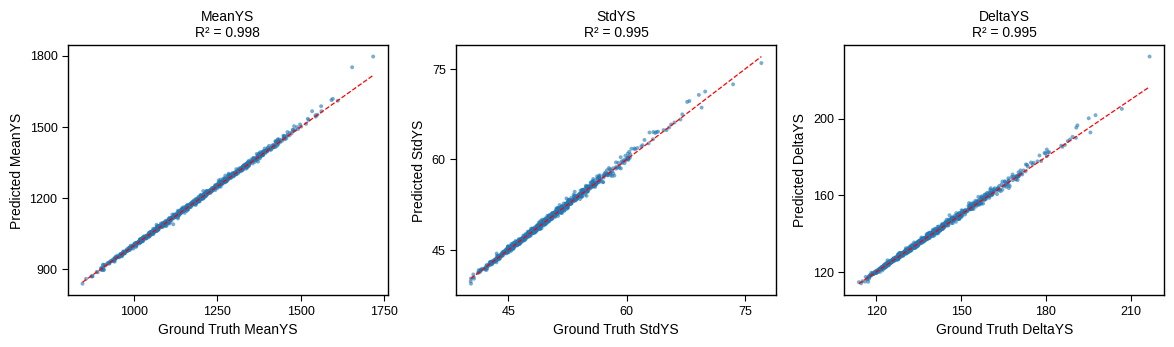

In [10]:
pred_outputs = generate_in_batches(df_prompts_pred["prompt"].tolist(), TEMP_PRED, desc="Forward prediction")
df_outputs_pred = pd.DataFrame({"prediction": pred_outputs})
df_outputs_pred.to_csv(os.path.join(SAVE_DIR, "validation_predictions.csv"), index=False)

df_outputs_pred_parsed = pd.DataFrame([safe_parse(line) for line in df_outputs_pred["prediction"]])
df_outputs_pred_parsed = df_outputs_pred_parsed.reindex(columns=["Task"] + PROPS + ELEMS)
df_outputs_pred_parsed.to_csv(os.path.join(SAVE_DIR, "validation_pred_parsed.csv"), index=False)

# keep rows where every predicted property was recovered
ok = df_outputs_pred_parsed[PROPS].notna().all(axis=1)
print(f"{ok.sum()} / {len(ok)} predictions parsed")
parity_plots(
    {k: df_pred_gt.loc[ok, k].astype(float).values for k in PROPS},
    {k: df_outputs_pred_parsed.loc[ok, k].astype(float).values for k in PROPS},
    PROPS, "Ground Truth", "Predicted", save_name="YS_pred_vs_gt.png",
)

## 5. Inverse design (properties → composition)

Several compositions can meet the same property target, so agreement with the test alloy's composition is only a rough
guide; the round-trip check in section 6 tests whether the generated alloys actually hit their targets.

In [11]:
torch.cuda.empty_cache()
gene_outputs = generate_in_batches(df_prompts_gene["prompt"].tolist(), TEMP_GENE, desc="Inverse design")
df_outputs_gene = pd.DataFrame({"prediction": gene_outputs})
df_outputs_gene.to_csv(os.path.join(SAVE_DIR, "validation_generation.csv"), index=False)

# parse; malformed lines become NaN rows so everything stays aligned with df_gene_gt
df_gene_result_parsed = pd.DataFrame([safe_parse(line) for line in df_outputs_gene["prediction"]])
df_gene_result_parsed = df_gene_result_parsed.reindex(columns=["Task"] + PROPS + ELEMS)
df_gene_result_parsed.to_csv(os.path.join(SAVE_DIR, "validation_gene_parsed.csv"), index=False)

print("NaNs per column:\n", df_gene_result_parsed.isna().sum())
ok_gene = df_gene_result_parsed[ELEMS].notna().all(axis=1) & df_gene_gt[ELEMS].notna().all(axis=1)
print(f"{ok_gene.sum()} / {len(ok_gene)} generations parsed")

Inverse design: 100%|██████████| 63/63 [17:11<00:00, 16.37s/it]

NaNs per column:
 Task       511
MeanYS     511
StdYS      511
DeltaYS    511
Ti         550
Cr         548
Mo         549
Al         552
Nb         552
Co         553
Ni         551
dtype: int64
419 / 1000 generations parsed


outliers dropped per element: {'Ti': 5, 'Cr': 13, 'Mo': 17, 'Al': 4, 'Nb': 10, 'Co': 2, 'Ni': 10} (of 419 parsed)


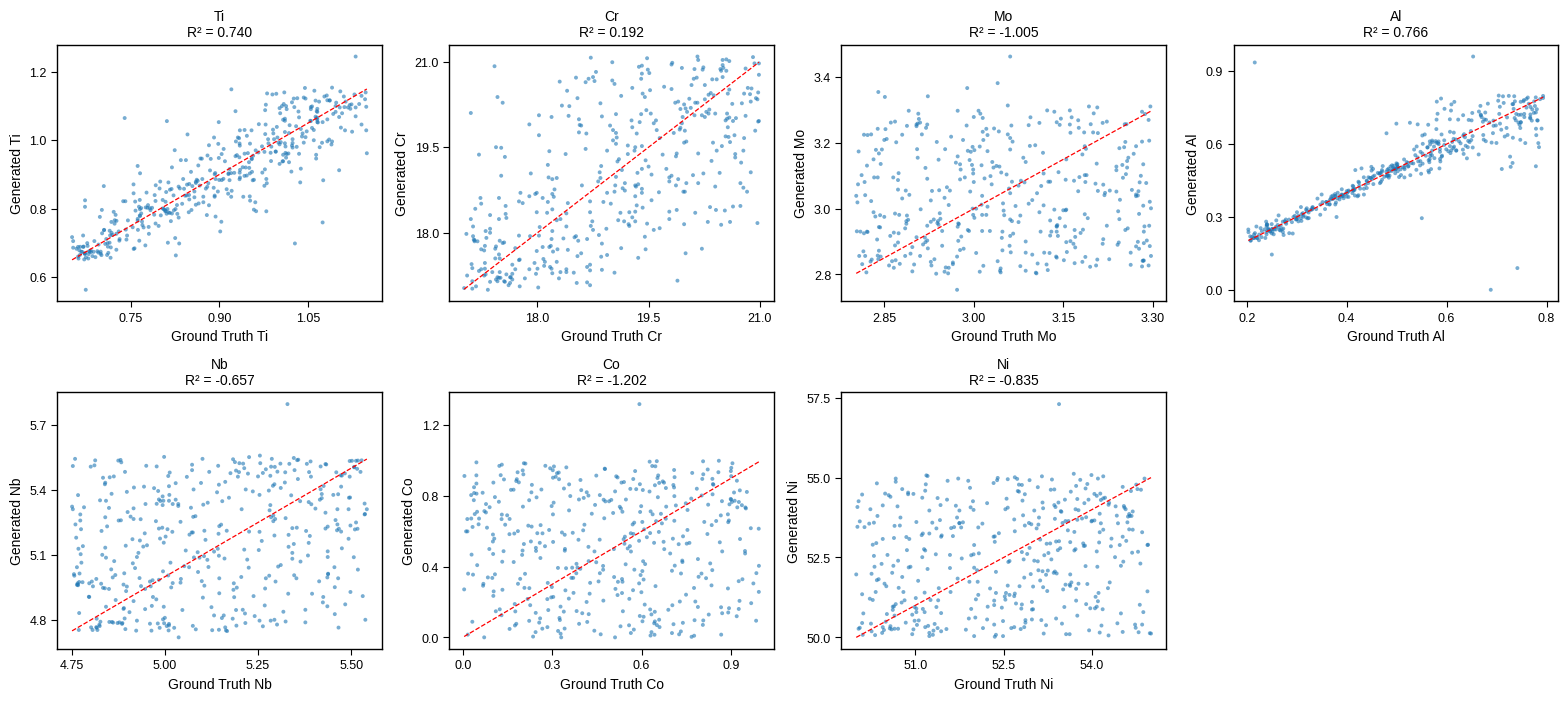

In [17]:
OUTLIER_K = 1.5   # larger = keep more points; None = no filtering

y_true_comp, y_gen_comp, n_dropped = {}, {}, {}
for k in ELEMS:
    t = df_gene_gt.loc[ok_gene, k].astype(float).values
    g = df_gene_result_parsed.loc[ok_gene, k].astype(float).values
    if OUTLIER_K is None:
        keep = np.ones_like(t, dtype=bool)
    else:
        q1, q3 = np.percentile(t, [25, 75])
        lo, hi = q1 - OUTLIER_K * (q3 - q1), q3 + OUTLIER_K * (q3 - q1)
        keep = (g >= lo) & (g <= hi) & (t >= lo) & (t <= hi)
    y_true_comp[k], y_gen_comp[k] = t[keep], g[keep]
    n_dropped[k] = int((~keep).sum())

print("outliers dropped per element:", n_dropped, f"(of {int(ok_gene.sum())} parsed)")

parity_plots(y_true_comp, y_gen_comp, ELEMS, "Ground Truth", "Generated",
             ncols=4, save_name="composition_gen_vs_gt.png")

## 6. Round-trip check (generated composition → predicted properties vs. target)

In [13]:
def reformat_prediction(text):
    """Turn a Gene001 output into a Pred001 prompt for the composition it generated."""
    text = text.replace("{Task:Gene", "{Task:Pred")              # 1. task Gene -> Pred
    text = re.sub(r"\{Property:\[.*?\]\}=>", "", text)          # 2. drop the {Property:...}=> block
    text = text.replace("]}", "]}=>{Property:")                   # 3. ask for the properties
    return text


# targets: the properties each generation was asked for (row-aligned with df_outputs_gene) 
df_gen_targets = df_gene_result_parsed[PROPS]

rt_prompts = df_outputs_gene["prediction"].apply(reformat_prediction).tolist()
rt_outputs = generate_in_batches(rt_prompts, TEMP_PRED, desc="Round trip")
df_gen_check = pd.DataFrame({"prediction": rt_outputs})
df_gen_check.to_csv(os.path.join(SAVE_DIR, "validation_gen_prop.csv"), index=False)

# outputs where a number was corrupted by a stray character
bad_mask = df_gen_check["prediction"].str.contains(r"[0-9]\s*G[eE][+-]?[0-9]", regex=True)
print("Number of problematic lines:", int(bad_mask.sum()))

df_gen_check_parsed = pd.DataFrame([safe_parse(line) for line in df_gen_check["prediction"]])
df_gen_check_parsed = df_gen_check_parsed.reindex(columns=["Task"] + PROPS + ELEMS)
df_gen_check_parsed.to_csv(os.path.join(SAVE_DIR, "df_gen_check_parsed.csv"), index=False)

ok_rt = df_gen_targets.notna().all(axis=1) & df_gen_check_parsed[PROPS].notna().all(axis=1) & ~bad_mask
print(f"{ok_rt.sum()} / {len(ok_rt)} round trips usable")

Round trip: 100%|██████████| 63/63 [17:38<00:00, 16.80s/it]

Number of problematic lines: 4
459 / 1000 round trips usable


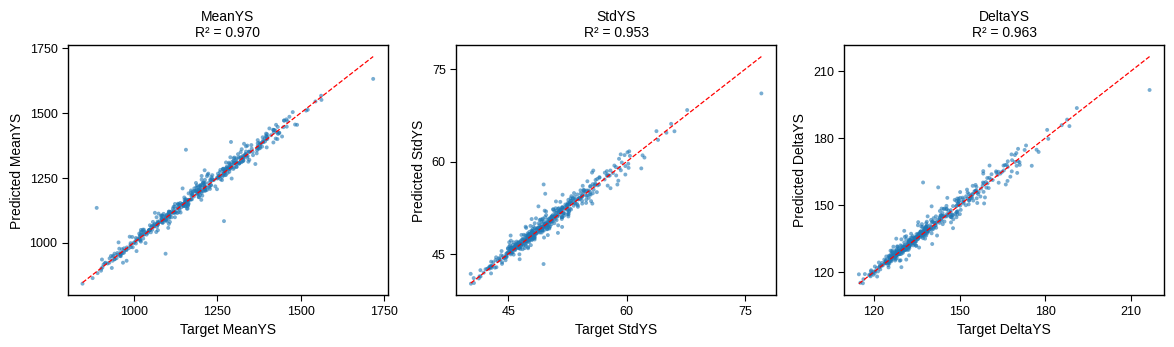

In [14]:
parity_plots(
    {k: df_gen_targets.loc[ok_rt, k].astype(float).values for k in PROPS},
    {k: df_gen_check_parsed.loc[ok_rt, k].astype(float).values for k in PROPS},
    PROPS, "Target", "Predicted", save_name="YS_gen_vs_check.png",
)